# Character-Level GPT from Scratch: Training, Interpretability and Ablation on Tiny Shakespeare

A decoder-only Transformer (GPT) written from scratch in PyTorch and trained to predict the next character on Tiny Shakespeare (1.1M characters, 65-symbol vocabulary). The notebook goes beyond training: it verifies the implementation with sanity checks, compares against a bigram baseline, inspects attention patterns, and measures how much each attention head matters by ablating it.

**Main results (preset `tiny`, 0.82M parameters, 3,000 steps, CPU, seed 1337)**

| Model | Validation loss (nats/char) | Bits/char | Perplexity |
|---|---|---|---|
| Uniform guess | 4.174 | 6.022 | 65.0 |
| Bigram baseline | 2.482 | 3.581 | 11.96 |
| **GPT-tiny (4 layers, 4 heads, d=128)** | **1.626** | **2.346** | **5.08** |

- The GPT reduces validation loss by 0.86 nats (35%) relative to the bigram baseline.
- Head ablation: zero-ablating **layer 0, head 0** raises validation loss by **+0.48**, the largest effect. The next largest are layer 0 heads 3 and 2 (+0.17, +0.09), and no head in later layers changes the loss by more than +0.021.

**Contents**
1. Setup and reproducibility, 2. Data, 3. Batching and evaluation, 4. Training utilities, 5. Bigram baseline, 6. Attention intuition, 7. Transformer, 8. Sanity checks, 9. Training, 10. Results, 11. Generation, 12. Attention heatmaps, 13. Head ablation, 14. Depth sweep (optional; not part of the reported results), followed by the summary and limitations.

**Reproducibility.** All randomness is seeded (`SEED = 1337`); evaluation uses fixed batches, so numbers are comparable across models and checkpoints. Presets (`tiny`, `medium`, `full`) are selected automatically from the available hardware; the reported numbers use `tiny`.

*Based on the architecture of Karpathy's "Let's build GPT" (nanoGPT lineage); implementation, checks, baselines and analyses are written for this notebook.*

## 1. Setup



In [1]:
import os, math, time, random, urllib.request
from contextlib import contextmanager

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

# Folders used by this notebook
for folder in ["data", "figures", "results", "writeup"]:
    os.makedirs(folder, exist_ok=True)

In [2]:
SEED = 1337
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.14.0+cpu | device: cpu


### 1.1 Hyperparameters

In [3]:
PRESETS = {
    "tiny":   dict(batch_size=32, block_size=64,  n_embd=128, n_head=4, n_layer=4, dropout=0.0,
                   learning_rate=1e-3, max_iters=3000, eval_interval=300, eval_iters=100),
    "medium": dict(batch_size=64, block_size=128, n_embd=256, n_head=4, n_layer=6, dropout=0.1,
                   learning_rate=6e-4, max_iters=4000, eval_interval=500, eval_iters=100),
    "full":   dict(batch_size=64, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.2,
                   learning_rate=3e-4, max_iters=5000, eval_interval=500, eval_iters=200),
}

# Parameter counts of the three presets (used later as a correctness check)
EXPECTED_PARAMS = {"tiny": 816_705, "medium": 4_800_577, "full": 10_788_929}

### 1.2 Switches



In [4]:
# ---- Switches ----
PRESET = None         # None = automatic (GPU -> "medium", CPU -> "tiny"). Or force "tiny" / "medium" / "full".
DRYRUN = False        # True = very short run (about 100 steps) to check that every cell works.
USE_AMP = False       # fp16 mixed precision, CUDA GPU only. Turn off if the loss becomes nan.
RUN_ABLATION = True   # Section 13
RUN_SWEEPS = False    # Section 14 (optional and the slowest part: about 20 minutes on CPU). Set True to run it.

# ---- Apply the choice (no need to edit below) ----
if PRESET is None:
    PRESET = "medium" if device == "cuda" else "tiny"
if device == "cpu" and PRESET != "tiny":
    print("No GPU found -> switching to the 'tiny' preset")
    PRESET = "tiny"

globals().update(PRESETS[PRESET])    # creates batch_size, block_size, n_embd, ... as normal variables

BIGRAM_STEPS = 3000
SWEEP_STEPS = 2000 if device == "cuda" else 1500   # long enough that models are past the early-training phase
SWEEP_SEEDS = (0, 1, 2)

if DRYRUN:
    max_iters, eval_interval, eval_iters = 100, 50, 20
    BIGRAM_STEPS = 200
    SWEEP_STEPS, SWEEP_SEEDS = 30, (0, 1)

print("preset:", PRESET, "| DRYRUN:", DRYRUN)
print({name: globals()[name] for name in PRESETS[PRESET]})

preset: tiny | DRYRUN: False
{'batch_size': 32, 'block_size': 64, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.0, 'learning_rate': 0.001, 'max_iters': 3000, 'eval_interval': 300, 'eval_iters': 100}


## 2. Data



In [5]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
path = "data/input.txt"

# A previous failed download can leave an empty file behind. Remove it so we download again.
if os.path.exists(path) and os.path.getsize(path) < 1_000_000:
    print("bad/empty file found, deleting:", os.path.getsize(path), "bytes")
    os.remove(path)
if not os.path.exists(path):
    urllib.request.urlretrieve(URL, path)

with open(path, "r", encoding="utf-8") as f:
    text = f.read()

print("characters:", len(text), "(expected 1115394)")
assert len(text) > 1_000_000, "Text is empty or wrong: download failed. Save the file manually as data/input.txt"
print(text[:200])

characters: 1115394 (expected 1115394)
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


### 2.1 Vocabulary



In [6]:
chars = sorted(set(text))               # every distinct character, in a fixed order
vocab_size = len(chars)
print("vocab size:", vocab_size, "(expected 65)")
print(repr("".join(chars)))

stoi = {ch: i for i, ch in enumerate(chars)}    # character -> integer
itos = {i: ch for ch, i in stoi.items()}        # integer   -> character

def encode(s):
    """String -> list of integers."""
    return [stoi[c] for c in s]

def decode(ids):
    """List of integers -> string."""
    return "".join(itos[i] for i in ids)

print(encode("hii there"), "->", decode(encode("hii there")))
assert decode(encode(text[:20])) == text[:20]

vocab size: 65 (expected 65)
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
[46, 47, 47, 1, 58, 46, 43, 56, 43] -> hii there


### 2.2 Train / validation split

The first 90% of the text is used for training, the last 10% for validation. The split is by position (not
shuffled) because the text is one continuous stream. Validation data is never used to update the weights.

In [7]:
data = torch.tensor(encode(text), dtype=torch.long)
split_at = int(0.9 * len(data))
train_data, val_data = data[:split_at], data[split_at:]
print("train tokens:", len(train_data), "| val tokens:", len(val_data))

train tokens: 1003854 | val tokens: 111540


## 3. Batching and evaluation



In [8]:
def get_batch(split, gen=None):
    """Return a batch (x, y). x: random windows of block_size characters, y: the same windows shifted by one."""
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,), generator=gen)   # random start positions
    x = torch.stack([d[i : i + block_size] for i in ix])
    y = torch.stack([d[i + 1 : i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

# Look at one batch
xb, yb = get_batch("train")
print(xb.shape, yb.shape)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "targets are not x shifted by one!"
for t in range(3):
    print(f"  context {decode(xb[0, : t + 1].tolist())!r:10} -> target {decode([yb[0, t].item()])!r}")

torch.Size([32, 64]) torch.Size([32, 64])
  context 'l'        -> target 'e'
  context 'le'       -> target '.'
  context 'le.'      -> target ' '


### 3.1 Measuring the loss

`estimate_loss` averages the loss over `eval_iters` batches. It always uses **the same fixed batches** (the
random generator is re-seeded each time), so numbers from different models or different checkpoints
are directly comparable. Training batches stay random.

**Note.** Each evaluation draws `eval_iters × batch_size × block_size` characters (204,800 for the `tiny` preset) from random, overlapping windows. This is more than the 111,540 validation characters, so the reported validation loss is an estimate on sampled windows, not an exact pass over the validation set.

In [9]:
@torch.no_grad()
def estimate_loss(model):
    """Average train and validation loss on fixed evaluation batches."""
    out = {}
    model.eval()
    for split in ("train", "val"):
        gen = torch.Generator().manual_seed(999)       # same batches on every call
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split, gen)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

## 4. Training utilities

`train_model` trains with AdamW (constant learning rate), evaluates every `eval_interval` steps on fixed batches, and saves the checkpoint with the best validation loss. `sample` generates text from a model, optionally from a prompt and at a chosen temperature.

In [10]:
def train_model(model, lr, steps, tag, use_amp=False, ckpt_path=None, log=True):
    """Train `model` for `steps` steps with AdamW. Returns the loss history as a list of dicts.
    If ckpt_path is given, the weights with the best validation loss are saved there."""
    use_amp = use_amp and device == "cuda"
    model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    amp_device = "cuda" if device == "cuda" else "cpu"

    history, best_val, t0 = [], float("inf"), time.time()
    for it in range(steps + 1):
        # --- periodic evaluation ---
        if it % eval_interval == 0 or it == steps:
            est = estimate_loss(model)
            history.append(dict(step=it, train=est["train"], val=est["val"], secs=time.time() - t0))
            if log:
                print(f"[{tag}] step {it:5d} | train {est['train']:.4f} | val {est['val']:.4f} "
                      f"| {time.time() - t0:5.0f}s", flush=True)
            if ckpt_path and est["val"] < best_val:
                best_val = est["val"]
                torch.save(model.state_dict(), ckpt_path)
        if it == steps:
            break

        # --- one training step ---
        xb, yb = get_batch("train")
        with torch.autocast(device_type=amp_device, dtype=torch.float16, enabled=use_amp):
            _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
    return history

In [11]:
@torch.no_grad()
def sample(model, n=500, temperature=1.0, start=None):
    """Generate n characters. Higher temperature = more random. `start` is an optional prompt."""
    model.eval()
    if start is None:
        ctx = torch.zeros((1, 1), dtype=torch.long, device=device)      # token 0 is the newline character
    else:
        ctx = torch.tensor([encode(start)], dtype=torch.long, device=device)
    out = model.generate(ctx, n, temperature=temperature)
    model.train()
    return decode(out[0].tolist())

## 5. Baseline: the bigram model

Any result should be compared with a simple reference. A bigram model predicts the next character from the current character only (a 65x65 table of scores). It cannot use any longer context, so it sets the level a model must beat to be using context at all. It converges to validation loss **2.482**; its samples contain plausible letter pairs but almost no real words. Its initial loss (4.72) is above ln(65) = 4.17 because `nn.Embedding` is initialised from N(0, 1); the GPT below uses std 0.02, which gives an initial loss close to ln(65).

In [12]:
class BigramLanguageModel(nn.Module):
    """Predicts the next character from the current character only."""

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)   # row = scores for the next char

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)                            # (B, T, vocab_size)
        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -block_size:])
            probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)       # distribution over next char
            idx = torch.cat([idx, torch.multinomial(probs, num_samples=1)], dim=1)
        return idx

In [13]:
torch.manual_seed(SEED)
bigram = BigramLanguageModel().to(device)

_, l0 = bigram(*get_batch("train"))
print("initial loss:", round(l0.item(), 3), "| ln(vocab) =", round(math.log(vocab_size), 3))

bigram_hist = train_model(bigram, lr=1e-2, steps=BIGRAM_STEPS, tag="bigram")
bigram_final = estimate_loss(bigram)
print("bigram final:", {k: round(v, 4) for k, v in bigram_final.items()}, "(expected val about 2.5)")
print(sample(bigram, 300))

initial loss: 4.722 | ln(vocab) = 4.174
[bigram] step     0 | train 4.7268 | val 4.7275 |     0s
[bigram] step   300 | train 2.6839 | val 2.6939 |     2s
[bigram] step   600 | train 2.5071 | val 2.5220 |     3s
[bigram] step   900 | train 2.4812 | val 2.5023 |     4s
[bigram] step  1200 | train 2.4721 | val 2.4912 |     6s
[bigram] step  1500 | train 2.4672 | val 2.4873 |     7s
[bigram] step  1800 | train 2.4643 | val 2.4845 |     8s
[bigram] step  2100 | train 2.4627 | val 2.4846 |    10s
[bigram] step  2400 | train 2.4614 | val 2.4841 |    11s
[bigram] step  2700 | train 2.4602 | val 2.4825 |    12s
[bigram] step  3000 | train 2.4602 | val 2.4820 |    13s
bigram final: {'train': 2.4602, 'val': 2.482} (expected val about 2.5)

W:
S:
Tof my RGorothe alll s y I t haicerce o lokicechy wovethorico thstsen. gibyorns af y fe, gulld he s ou w keemparen'd?
The:
Ayos,Danco ors If her'?
Lanco,
s ca bs fay s. ak,
FOFo th wechat h l I re bo hid'larte.



Nomure, ofoncen tleshou f dom in nontin r

## 6. Self-attention intuition



In [14]:
torch.manual_seed(42)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

# Version 1: loops
xbow = torch.zeros(B, T, C)
for b in range(B):
    for t in range(T):
        xbow[b, t] = x[b, : t + 1].mean(dim=0)

# Version 2: matrix multiplication with a normalised lower-triangular matrix
w2 = torch.tril(torch.ones(T, T))
w2 = w2 / w2.sum(dim=1, keepdim=True)
xbow2 = w2 @ x

# Version 3: masked softmax (future positions get -inf, so softmax gives them weight 0)
tril_ = torch.tril(torch.ones(T, T))
w3 = torch.zeros(T, T).masked_fill(tril_ == 0, float("-inf"))
w3 = F.softmax(w3, dim=-1)
xbow3 = w3 @ x

same_12 = torch.allclose(xbow, xbow2, atol=1e-6)
same_13 = torch.allclose(xbow, xbow3, atol=1e-6)
print("v1 == v2:", same_12, "| v1 == v3:", same_13)
assert same_12 and same_13
print(w3)      # row t: equal weight on positions 0..t, zero on the future

v1 == v2: True | v1 == v3: True
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])


### 6.1 Why attention scores are scaled

Attention scores are `query . key`. For vectors of size `head_size`, these scores have variance about
`head_size`. If they are left unscaled, the softmax becomes almost one-hot (one position gets all the
weight) and learning is poor. Dividing by `sqrt(head_size)` brings the variance back to about 1.

In [15]:
head_size_demo = 64
k_demo = torch.randn(4, 8, head_size_demo)
q_demo = torch.randn(4, 8, head_size_demo)

raw = q_demo @ k_demo.transpose(-2, -1)
scaled = raw * head_size_demo ** -0.5

print("variance raw:", round(raw.var().item(), 1), "| scaled:", round(scaled.var().item(), 2))
print("softmax raw   :", F.softmax(raw[0, 0], dim=-1)[:4].numpy().round(3), "(peaked)")
print("softmax scaled:", F.softmax(scaled[0, 0], dim=-1)[:4].numpy().round(3), "(flatter)")

_ = torch.manual_seed(SEED)       # restore the global seed

variance raw: 61.6 | scaled: 0.96
softmax raw   : [0.651 0.002 0.    0.   ] (peaked)
softmax scaled: [0.292 0.142 0.046 0.112] (flatter)


Unscaled scores have variance about `head_size` (61.6 here for head size 64), which makes the softmax very peaked; after scaling the variance is about 1 (0.96) and the weights are spread out.

## 7. The Transformer

*Design note:* `Head` and `MultiHeadAttention` read `n_embd`, `block_size` and `dropout` from notebook-level variables, while `Block` and `FeedForward` take arguments. This is deliberate: the sweeps in Section 14 change these variables with `override()` and build a fresh model inside it.


In [16]:
class Head(nn.Module):
    """One head of causal self-attention."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # Lower-triangular mask: position t may only look at positions 0..t
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                     # (B, T, head_size)
        q = self.query(x)                                   # (B, T, head_size)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # attention scores (B, T, T), scaled
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))   # hide the future
        wei = F.softmax(wei, dim=-1)                        # each row sums to 1
        wei = self.dropout(wei)
        return wei @ self.value(x)                          # weighted sum of values (B, T, head_size)

In [17]:
class MultiHeadAttention(nn.Module):
    """Several attention heads in parallel, then a linear projection."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)    # concatenate the heads
        return self.dropout(self.proj(out))

In [18]:
class FeedForward(nn.Module):
    """A small two-layer network applied to every position separately."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),     # expand 4x
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),     # project back
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [19]:
class Block(nn.Module):
    """One Transformer block: attention, then feed-forward, each with LayerNorm and a residual connection."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

In [20]:
class GPTLanguageModel(nn.Module):
    """Character-level GPT: embeddings -> n_layer blocks -> LayerNorm -> linear layer."""

    def __init__(self):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)        # what the character is
        self.position_embedding_table = nn.Embedding(block_size, n_embd)     # where it is in the window
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        """Small random initial weights (normal, std 0.02)."""
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding_table(idx)                                      # (B, T, n_embd)
        pos = self.position_embedding_table(torch.arange(T, device=idx.device))   # (T, n_embd)
        x = self.blocks(tok + pos)
        logits = self.lm_head(self.ln_f(x))                                        # (B, T, vocab_size)
        if targets is None:
            return logits, None
        loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        """Extend idx (B, T) by max_new_tokens characters, sampling one at a time."""
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -block_size:])        # never feed more than block_size characters
            probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, num_samples=1)], dim=1)
        return idx

print("model classes defined")

model classes defined


## 8. Sanity checks



In [21]:
# Check 1: parameter count
torch.manual_seed(SEED)
check_model = GPTLanguageModel().to(device)
n_params = sum(p.numel() for p in check_model.parameters())
print(f"parameters: {n_params:,} (expected for '{PRESET}': {EXPECTED_PARAMS[PRESET]:,})")
assert n_params == EXPECTED_PARAMS[PRESET], "parameter count differs from the expected architecture"

parameters: 816,705 (expected for 'tiny': 816,705)


In [22]:
# Check 2: output shape and initial loss
xb, yb = get_batch("train")
logits, loss = check_model(xb, yb)

assert logits.shape == (batch_size, block_size, vocab_size), logits.shape
print("logits shape:", tuple(logits.shape))
print("initial loss:", round(loss.item(), 3), "| uniform guess ln(vocab) =", round(math.log(vocab_size), 3))
assert abs(loss.item() - math.log(vocab_size)) < 0.3, "initial loss is far from ln(vocab): check init and loss"

logits shape: (32, 64, 65)
initial loss: 4.213 | uniform guess ln(vocab) = 4.174


In [23]:
# Check 3: causality. Change the character at position t; predictions before t must not change.
check_model.eval()
with torch.no_grad():
    x = xb[:1].clone()
    t = block_size // 2
    logits_a, _ = check_model(x)

    x_changed = x.clone()
    x_changed[0, t] = (x_changed[0, t] + 1) % vocab_size
    logits_b, _ = check_model(x_changed)

past_unchanged = torch.allclose(logits_a[:, :t], logits_b[:, :t], atol=1e-5)
future_reacted = (logits_a[:, t:] - logits_b[:, t:]).abs().max().item() > 0
print("past unchanged by a later character:", past_unchanged)    # must be True
print("position t and later did react     :", future_reacted)    # must be True
assert past_unchanged and future_reacted, "causality check failed: the attention mask is wrong"
del check_model

past unchanged by a later character: True
position t and later did react     : True


In [24]:
# Check 4: overfit one batch. Train on the SAME batch repeatedly; the loss should drop close to 0.
torch.manual_seed(SEED)
tmp_model = GPTLanguageModel().to(device).eval()      # eval mode switches dropout off
tmp_opt = torch.optim.AdamW(tmp_model.parameters(), lr=1e-3)
xb, yb = get_batch("train")

for i in range(201):
    _, batch_loss = tmp_model(xb, yb)
    tmp_opt.zero_grad(set_to_none=True)
    batch_loss.backward()
    tmp_opt.step()
    if i % 50 == 0:
        print(f"  overfit-one-batch step {i:3d} | loss {batch_loss.item():.4f}")

assert batch_loss.item() < 0.5, "cannot overfit one batch: bug in the model or the training step"
del tmp_model, tmp_opt
print("\nALL SANITY CHECKS PASSED")

  overfit-one-batch step   0 | loss 4.2130
  overfit-one-batch step  50 | loss 0.9845
  overfit-one-batch step 100 | loss 0.0532
  overfit-one-batch step 150 | loss 0.0325
  overfit-one-batch step 200 | loss 0.0272

ALL SANITY CHECKS PASSED


All four checks pass: parameter count matches the architecture, the initial loss is close to ln(65) = 4.17, a later character never changes earlier predictions (causal mask correct), and the model can overfit a single batch (loss 4.21 to 0.03).

## 9. Training the GPT



In [25]:
CKPT = f"results/gpt_{PRESET}_best.pt"

torch.manual_seed(SEED)
model = GPTLanguageModel().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters | preset {PRESET} | steps {max_iters}")

hist = train_model(model, lr=learning_rate, steps=max_iters, tag=PRESET, use_amp=USE_AMP, ckpt_path=CKPT)
pd.DataFrame(hist).to_csv(f"results/loss_{PRESET}.csv", index=False)

model.load_state_dict(torch.load(CKPT, map_location=device))      # go back to the best-validation weights
final = estimate_loss(model)
print("best checkpoint ->", {k: round(v, 4) for k, v in final.items()})

816,705 parameters | preset tiny | steps 3000
[tiny] step     0 | train 4.2181 | val 4.2144 |    22s
[tiny] step   300 | train 2.0933 | val 2.1390 |   148s
[tiny] step   600 | train 1.7997 | val 1.9143 |   292s
[tiny] step   900 | train 1.6620 | val 1.8100 |   462s
[tiny] step  1200 | train 1.5903 | val 1.7588 |   697s
[tiny] step  1500 | train 1.5328 | val 1.7105 |   871s
[tiny] step  1800 | train 1.5016 | val 1.6884 |   951s
[tiny] step  2100 | train 1.4746 | val 1.6536 |  1076s
[tiny] step  2400 | train 1.4505 | val 1.6378 |  1203s
[tiny] step  2700 | train 1.4329 | val 1.6381 |  1325s
[tiny] step  3000 | train 1.4193 | val 1.6259 |  1443s
best checkpoint -> {'train': 1.4193, 'val': 1.6259}


The model trains stably. Validation loss trends down over training and is lowest at the final step (1.626, train 1.419); between steps 2,400 and 2,700 it is flat (1.638 and 1.638). The train/validation gap is moderate (about 0.21), so this small model looks limited by training length and size rather than by overfitting. Longer training or the `medium`/`full` presets would be expected to lower the loss further, but this was not tested here.

## 10. Results: loss curves and comparison


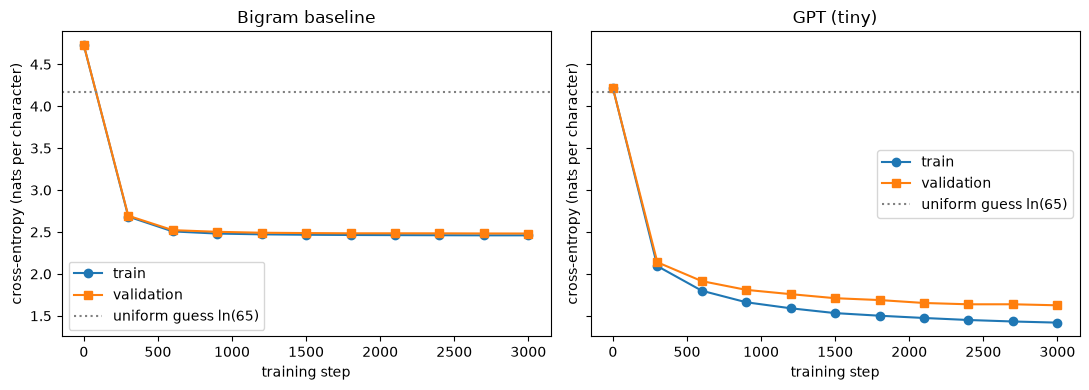

In [26]:
hb, hg = pd.DataFrame(bigram_hist), pd.DataFrame(hist)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (name, h) in zip(ax, [("Bigram baseline", hb), (f"GPT ({PRESET})", hg)]):
    a.plot(h.step, h.train, marker="o", label="train")
    a.plot(h.step, h.val, marker="s", label="validation")
    a.axhline(math.log(vocab_size), ls=":", color="gray", label="uniform guess ln(65)")
    a.set(title=name, xlabel="training step", ylabel="cross-entropy (nats per character)")
    a.legend()
plt.tight_layout()
plt.savefig(f"figures/loss_curves_{PRESET}.png", dpi=150)
plt.show()

In [27]:
# Both models are compared with the SAME rule: the final estimate_loss value
# (for the GPT: after reloading its best checkpoint).
summary = pd.DataFrame({
    "model": ["uniform guess", "bigram", f"GPT-{PRESET}"],
    "val loss": [math.log(vocab_size), bigram_final["val"], final["val"]],
    "perplexity": [vocab_size, math.exp(bigram_final["val"]), math.exp(final["val"])],
}).round(3)
summary.to_csv("results/summary.csv", index=False)
print(summary)
print("\nNote: the checkpoint was chosen by validation loss, so this validation number can be slightly optimistic.")

           model  val loss  perplexity
0  uniform guess     4.174      65.000
1         bigram     2.482      11.965
2       GPT-tiny     1.626       5.083

Note: the checkpoint was chosen by validation loss, so this validation number can be slightly optimistic.


Values are in nats per character; bits per character = nats / ln 2. The checkpoint is chosen by validation loss on the same fixed batches that are reported, so the GPT's validation number is slightly optimistic (here the best checkpoint is the final step, so the effect is negligible).

## 11. Text generation


In [28]:
out = sample(model, 1000)
print(out)
with open(f"results/sample_{PRESET}.txt", "w", encoding="utf-8") as f:
    f.write(out)


This terr, and I am therefore to so course
Struckly the can on the mirate of these their fair:
Sweet fair is not in't, my deserve them!
Mishame the duke to take and Engloking at line,
A deposider for forweeti
Messagetioy.

LUCRIANA:
I am that I am new put thyself;
Nor Clauffords it slandding title to like.

ROMEO:
Come, executed, the fire the queen? O, away?
Youary sent thee that Clares gentle God,
Nor drays, thrust mokily strange,
The crowle from ock'd my majesty
Of ison Quaiths, asided best knee, your lord,
Or more rendified may stom, with truth,
I know thee: presing stand love how your rumor,
To much stonest thing fathings as strout,
As three with the fire would aged, To thee.

VAULIA:
When, by the fave?

POLIXENES:
It impress shall I bear my brothen's for the great,
Ashall clufford'st fool
Thereof to the Giess?

Give Sentry:
I knowlet stimorize to the queen:
Arm distraites thy remains on. as yet these?

VAUMILLIA:
I fear Grarlet, that I fen
PArdon perform is every.

QUEEN MAXIRANA

In [29]:
print("==== prompted with 'ROMEO:' ====")
print(sample(model, 300, start="ROMEO:"))

for temp in (0.5, 1.0, 1.3):
    print(f"\n==== temperature {temp} ====")
    print(sample(model, 300, temperature=temp))

==== prompted with 'ROMEO:' ====
ROMEO:
Sire, and this eyes despair, stath me fear again
And baggare, by minion. Within badies them.

LEONTES:
Ay, which is fainted as with us.

LEONTES:
Thy life with use the three--
Jutwives Menial their tomory, tribuness cands those:
There thou queen, be may merely the mies,
To lelives them, deserve the

==== temperature 0.5 ====


First Murderer:
And then is a remember the most and stand to the dancient
The lies of heavens the nuptiers and and me the fled
And hear the heavy of this shame to ender this bear
To beseech you to say the deserve and thee,
The intenderst still the wing thee thee,
And the name of well the may sent t

==== temperature 1.0 ====

To me the not with a slaintain.

VAMILLO:
Would have you lie that's a foreiveys fronger!
Heirly Engless; thim nor it in double say,
When in humonfuried; uf the deel, heard shority;
And will'd to-mold.

YORK:
'Twas I take thee that tide see them encounterCy;
But dissagm, mea; no, for Richard Stour-de

=

Qualitatively, the model has learned the *format* of the play (speaker names in capitals followed by a colon, line breaks, punctuation) and many real words, but still produces non-words and incoherent sentences, which is expected at this size. Lower temperature gives more conservative but repetitive text; higher temperature gives more errors.

## 12. Attention heatmaps



In [30]:
@torch.no_grad()
def attention_pattern(model, idx, layer, head):
    """Return the (T, T) attention weights of one head, for the first sequence in idx."""
    assert layer < len(model.blocks)
    was_training = model.training
    model.eval()
    T = idx.shape[1]
    x = model.token_embedding_table(idx) + model.position_embedding_table(torch.arange(T, device=idx.device))
    for i, blk in enumerate(model.blocks):        # run the blocks before the chosen layer
        if i == layer:
            break
        x = blk(x)
    h = blk.sa.heads[head]                        # blk is now the chosen layer
    xin = blk.ln1(x)
    k, q = h.key(xin), h.query(xin)
    wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
    wei = wei.masked_fill(h.tril[:T, :T] == 0, float("-inf"))
    model.train(was_training)
    return F.softmax(wei, dim=-1)[0].cpu()

def plot_attention(model, s, layer=0, head=0):
    """Plot the attention heatmap of one head on the string s."""
    assert len(s) <= block_size
    idx = torch.tensor([encode(s)], dtype=torch.long, device=device)
    A = attention_pattern(model, idx, layer, head)
    labels = [c if c != "\n" else "\\n" for c in s]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(A, cmap="viridis")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(labels, fontsize=7)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(labels, fontsize=7)
    ax.set(xlabel="attended-to position (key)", ylabel="current position (query)",
           title=f"layer {layer}, head {head}")
    plt.tight_layout()
    plt.savefig(f"figures/attention_L{layer}_H{head}.png", dpi=150)
    plt.show()

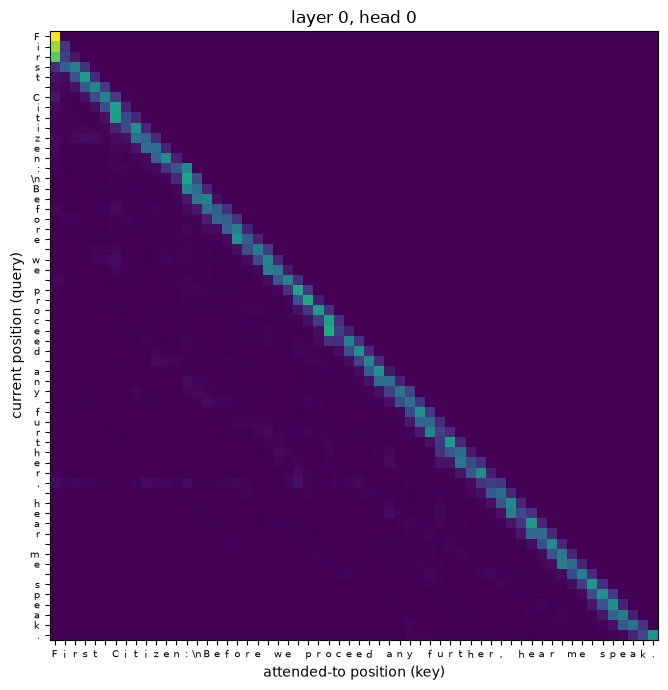

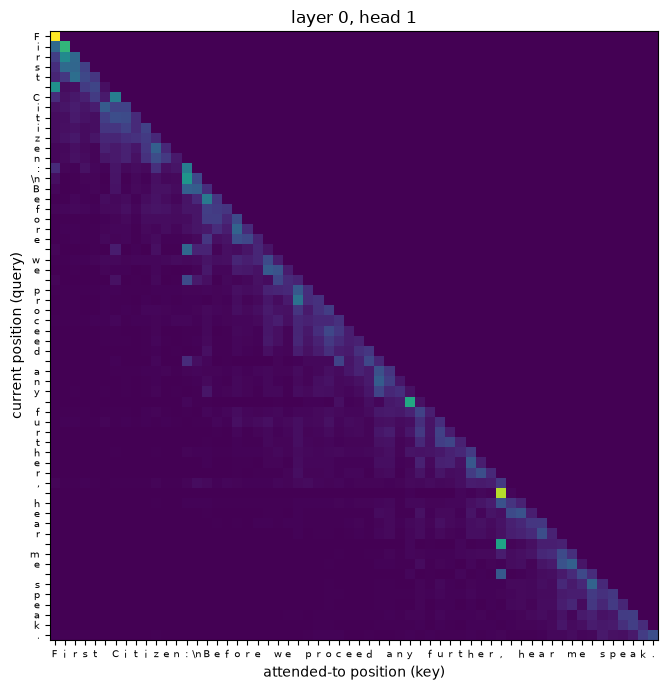

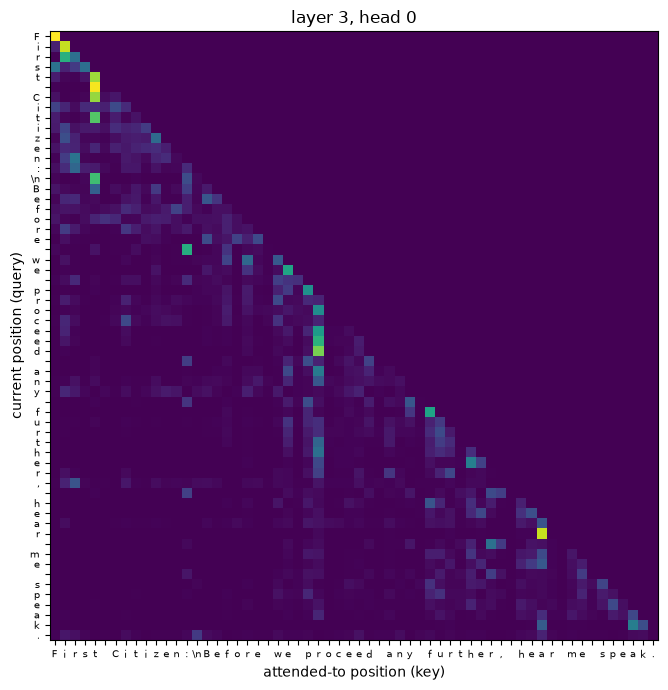

In [31]:
sentence = "First Citizen:\nBefore we proceed any further, hear me speak."[:block_size]

for layer, head in [(0, 0), (0, 1), (n_layer - 1, 0)]:      # two heads in the first layer, one in the last
    plot_attention(model, sentence, layer, head)

Heatmaps show, for each query position (row), how much attention goes to each earlier position (column); the upper triangle is empty because of the causal mask.

## 13. Head ablation

To estimate how much each head contributes, its output is replaced by zeros and the validation loss is re-measured (**zero-ablation**). The ablation is removed afterwards and the model is checked to be unchanged.

**Caveats.** (1) Zero-ablation can push activations off their normal distribution (mean-ablation is a gentler alternative). (2) Heads in earlier layers influence every later layer, so a large effect in layer 0 partly reflects its position, not only the head's own function. (3) Results are for one trained model, and head indices have no fixed meaning across training runs.

In [32]:
@torch.no_grad()
def val_loss_ablating(model, layer, head):
    """Validation loss with one head's output replaced by zeros."""
    h = model.blocks[layer].sa.heads[head]
    out_dim = h.value.out_features
    h.forward = lambda x: torch.zeros(x.shape[0], x.shape[1], out_dim, device=x.device)
    try:
        return estimate_loss(model)["val"]
    finally:
        del h.forward                 # always restore the original method

In [33]:
if RUN_ABLATION:
    base_val = estimate_loss(model)["val"]
    rows = []
    for L in range(n_layer):
        for H in range(n_head):
            v = val_loss_ablating(model, L, H)
            rows.append(dict(layer=L, head=H, val=v, delta=v - base_val))
    abl = pd.DataFrame(rows)
    abl.to_csv("results/head_ablation.csv", index=False)

    # The model must be exactly as before the experiment
    assert abs(estimate_loss(model)["val"] - base_val) < 1e-9, "ablation did not restore the model"

    print("baseline val loss:", round(base_val, 4))
    print("\nLargest increases in validation loss (delta):")
    print(abl.sort_values("delta", ascending=False).round(4).head(10).to_string(index=False))
else:
    print("ablation skipped (RUN_ABLATION = False)")

baseline val loss: 1.6259

Largest increases in validation loss (delta):
 layer  head    val  delta
     0     0 2.1061 0.4802
     0     3 1.7988 0.1729
     0     2 1.7207 0.0948
     0     1 1.6512 0.0253
     1     3 1.6472 0.0213
     2     1 1.6449 0.0190
     1     2 1.6413 0.0154
     2     0 1.6403 0.0144
     2     3 1.6398 0.0139
     2     2 1.6372 0.0113


**Result.** Zero-ablating layer 0, head 0 raises validation loss by +0.480, the largest effect, followed by layer 0 heads 3 and 2 (+0.173, +0.095). Layer 0 head 1 changes the loss by +0.025, and every head in layers 1-3 changes it by at most +0.021. In this model, the first layer's heads therefore matter most under zero-ablation, while individual heads in later layers matter little. Because of the caveats above, this does not by itself show that later heads are redundant or that layer 0 does the most useful attention work.

## 14. Depth sweep: validation loss vs. number of layers

Each configuration is trained with 3 seeds for a fixed, short budget and the mean and standard deviation of the final validation loss are reported. **Interpretation caveat:** with a short budget and a constant learning rate, deeper networks are often still in the early phase of training, so this experiment measures *speed of early training* more than the final benefit of depth. A difference smaller than the standard deviation is not a finding, and conclusions about depth should only be drawn from runs trained to convergence. Training batches use the same seed-controlled data stream for every configuration (the seed is set after the model is built).

**This section is optional and was not executed for the reported results** (`RUN_SWEEPS = False` in the switches). Set `RUN_SWEEPS = True` to run it (about 20 minutes on CPU for the `layers` sweep); no conclusion in this notebook depends on it.

In [34]:
@contextmanager
def override(**kw):
    """Temporarily change notebook-level hyperparameters, and restore them afterwards."""
    g = globals()
    old = {k: g[k] for k in kw}
    g.update(kw)
    try:
        yield
    finally:
        g.update(old)

# A fixed small configuration used by every sweep run
SWEEP_BASE = dict(batch_size=32, block_size=64, n_embd=128, n_head=4, n_layer=4, dropout=0.0,
                  eval_interval=100000, eval_iters=50)

def run_sweep(key, values, seeds=SWEEP_SEEDS, steps=SWEEP_STEPS, base=SWEEP_BASE):
    """For each value of hyperparameter `key`: train once per seed, report mean and std of the final val loss."""
    rows = []
    for v in values:
        vals = []
        for s in seeds:
            cfg = dict(base, **{key: v})
            if key == "block_size":                       # keep tokens per step constant (32 * 64 = 2048)
                cfg["batch_size"] = max(1, 2048 // v)
            with override(**cfg):
                torch.manual_seed(s)
                m = GPTLanguageModel()
                torch.manual_seed(s)          # same training-batch stream for every configuration
                h = train_model(m, lr=1e-3, steps=steps, tag=f"{key}={v}/seed{s}", log=False)
                vals.append(h[-1]["val"])
        rows.append({key: v,
                     "val_mean": np.mean(vals),
                     "val_std": np.std(vals, ddof=1) if len(vals) > 1 else 0.0,
                     "per_seed": [round(x, 4) for x in vals]})
        print(f"  {key}={v}: mean {rows[-1]['val_mean']:.4f} +- {rows[-1]['val_std']:.4f}", flush=True)
    return pd.DataFrame(rows)

In [35]:
SWEEP_OPTIONS = {
    "layers":  ("n_layer",    [1, 2, 4, 6]),
    "context": ("block_size", [8, 16, 32, 64, 128]),
    "heads":   ("n_head",     [1, 2, 4, 8]),
}
SWEEPS_TO_RUN = ["layers"]        # add "context" and/or "heads" to run more experiments (slower)

sweep_results = {}
if RUN_SWEEPS:
    print(f"sweeps: {SWEEP_STEPS} steps per run, seeds {SWEEP_SEEDS}")
    for name in SWEEPS_TO_RUN:
        key, values = SWEEP_OPTIONS[name]
        print("\nsweep:", name)
        df = run_sweep(key, values)
        df.to_csv(f"results/sweep_{name}.csv", index=False)
        sweep_results[name] = df
        print(df.round(4).to_string(index=False))
    print("\nReminder: a difference smaller than the std is NOT a finding.")
else:
    print("sweeps skipped (RUN_SWEEPS = False)")

sweeps skipped (RUN_SWEEPS = False)
